Sketch

In [3]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("data/raw/full_numpy_bitmap_aircraft carrier.npy")

data.shape

(116504, 784)

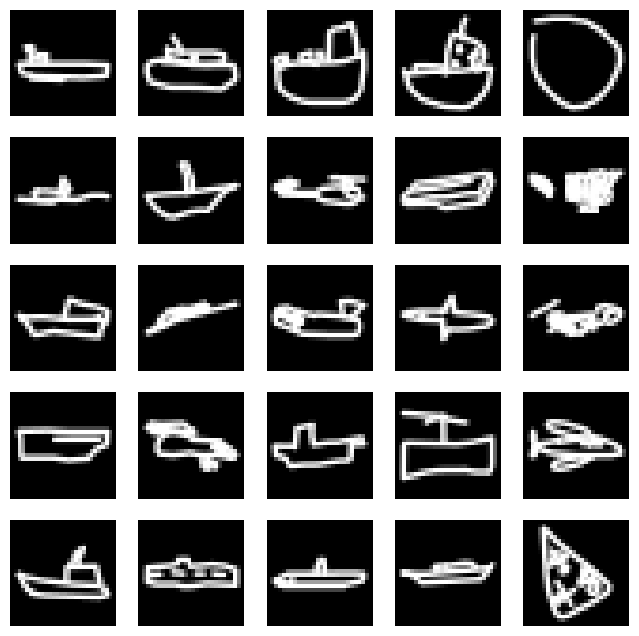

In [4]:
data = data[:500]

plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(data[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.show()

In [5]:
import numpy as np

index_categories = [
    "aircraft carrier", "airplane", "ambulance", "angel", "ant",
    "anvil", "basket", "basketball", "bat", "bed"
]

heldout_categories = ["alarm clock", "animal migration"]

data = np.load(
    "data/raw/full_numpy_bitmap_aircraft carrier.npy"
)

data.shape

(116504, 784)

In [6]:
data = np.load(
    "data/raw/full_numpy_bitmap_aircraft carrier.npy"
)
data = data[np.random.choice(len(data), 500, replace=False)]

data = data.reshape(-1, 28, 28)

gallery = data[:450]
queries = data[450:]

print(gallery.shape)
print(queries.shape)

(450, 28, 28)
(50, 28, 28)


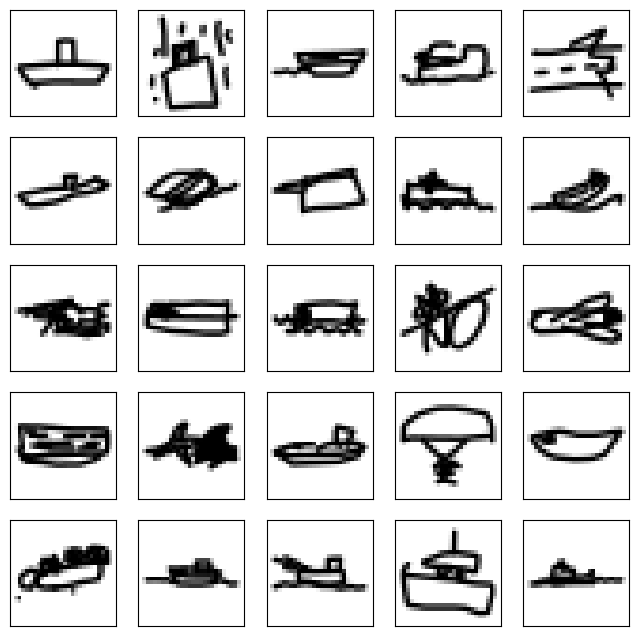

In [7]:
plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(gallery[i], cmap="binary")
    plt.xticks([])
    plt.yticks([])

plt.show()

In [8]:
from keras.applications import MobileNetV2

model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg"
)

model.trainable = False

C:\Users\user\AppData\Local\Temp\ipykernel_15912\3748034218.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  model = MobileNetV2(


In [9]:
model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, None,      │        864 │ input_layer[0][0] │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, None,      │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, None,      │          0 │ bn_Conv1[0][0]    │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │          0 │ expanded_conv_de… │
│ (ReLU)              │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, None,      │        512 │ expanded_conv_de… │
│ (Conv2D)            │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, None,      │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, None,      │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, None,      │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, None,      │          0 │ block_1_expand_B… │
│ (ReLU)              │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, None,      │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, None,      │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, None,      │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, None,      │          0 │ block_1_depthwis… │
│ (ReLU)              │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, None,      │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
import os

files = os.listdir("data/raw")

for file in files:
    print(file)

full_numpy_bitmap_aircraft carrier.npy
full_numpy_bitmap_airplane.npy
full_numpy_bitmap_alarm clock.npy
full_numpy_bitmap_ambulance.npy
full_numpy_bitmap_angel.npy
full_numpy_bitmap_animal migration.npy
full_numpy_bitmap_ant.npy
full_numpy_bitmap_anvil.npy
full_numpy_bitmap_apple.npy.opdownload
full_numpy_bitmap_arm.npy.opdownload
full_numpy_bitmap_asparagus.npy.opdownload
full_numpy_bitmap_axe.npy.opdownload
full_numpy_bitmap_backpack.npy.opdownload
full_numpy_bitmap_banana.npy.opdownload
full_numpy_bitmap_bandage.npy.opdownload
full_numpy_bitmap_barn.npy.opdownload
full_numpy_bitmap_baseball bat.npy.opdownload
full_numpy_bitmap_baseball.npy.opdownload
full_numpy_bitmap_basket.npy
full_numpy_bitmap_basketball.npy
full_numpy_bitmap_bat.npy.opdownload
full_numpy_bitmap_bed.npy
full_numpy_bitmap_bee.npy.opdownload
